In [1]:
import re
import requests
import pandas as pd
import matplotlib.pyplot as plt

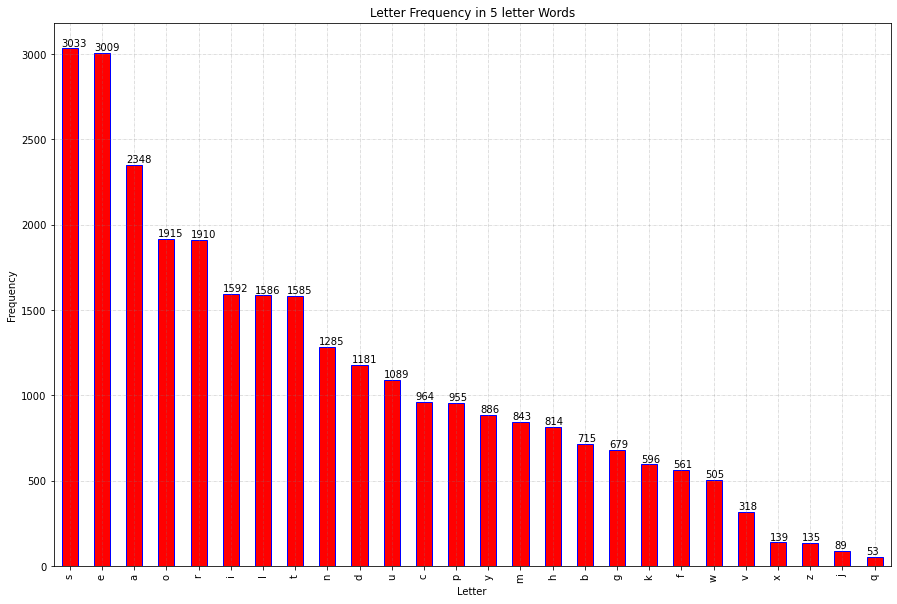

In [2]:
f = open("5-letter-words")
words_str = f.read()
f.close

re.findall(r"n?(\w{5})", words_str)
words = re.findall(r"n?(\w{5})", words_str)

letter_frequency = {}
for word in words:
    for i in range(5):
        letter = word[i]
        if letter not in letter_frequency:
            letter_frequency[letter] = 1
        else:
            letter_frequency[letter] += 1
            
sorted_letters = {k:v for (k, v) in sorted(letter_frequency.items(), key=lambda x: x[1], reverse = True)}
wordle_letter_popularity = pd.DataFrame(sorted_letters.items(), columns = ["Letter", "Frequency"])


ax1 = wordle_letter_popularity.plot.bar(x = "Letter", y = "Frequency", legend = False, 
                                       figsize = (15,10), width = .5, color = 'red', edgecolor = "blue")
ax1.set_ylabel("Frequency")
ax1.set_title("Letter Frequency in 5 letter Words")
ax1.grid(b = True, color ='grey',
        linestyle ='-.', linewidth = 0.5,
        alpha = 0.5)

for i in range(len(sorted_letters.items())):
    ax1.annotate(wordle_letter_popularity["Frequency"][i], (i - .25, wordle_letter_popularity["Frequency"][i] + 15))            


In [3]:
sorted_letters

{'s': 3033,
 'e': 3009,
 'a': 2348,
 'o': 1915,
 'r': 1910,
 'i': 1592,
 'l': 1586,
 't': 1585,
 'n': 1285,
 'd': 1181,
 'u': 1089,
 'c': 964,
 'p': 955,
 'y': 886,
 'm': 843,
 'h': 814,
 'b': 715,
 'g': 679,
 'k': 596,
 'f': 561,
 'w': 505,
 'v': 318,
 'x': 139,
 'z': 135,
 'j': 89,
 'q': 53}

In [4]:
letter_counts_per_word = []
for word in words:
    curr_count = 0
    for letter in letter_frequency:
        if letter in word:
            curr_count += letter_frequency[letter]
    letter_counts_per_word.append(curr_count)
    
usage_dict = {}
for i in range(len(words)):
    usage_dict[words[i]] = letter_counts_per_word[i]
    
sorted_usage = {k:v for (k, v) in sorted(usage_dict.items(), key=lambda x: x[1], reverse = True)}



#for i in range(len(sorted_letters.items())):
 #   ax.annotate(wordle_letter_popularity["Frequency"][i], (i - .25, wordle_letter_popularity["Frequency"][i] + 15))            



In [5]:
sorted_usage

{'arose': 12215,
 'raise': 11892,
 'arise': 11892,
 'aloes': 11891,
 'stoae': 11890,
 'laser': 11886,
 'earls': 11886,
 'reals': 11886,
 'tears': 11885,
 'rates': 11885,
 'stare': 11885,
 'aster': 11885,
 'tares': 11885,
 'snare': 11585,
 'earns': 11585,
 'nears': 11585,
 'saner': 11585,
 'nares': 11585,
 'aisle': 11568,
 'least': 11561,
 'tales': 11561,
 'steal': 11561,
 'slate': 11561,
 'stale': 11561,
 'teals': 11561,
 'tesla': 11561,
 'taels': 11561,
 'stela': 11561,
 'reads': 11481,
 'dares': 11481,
 'dears': 11481,
 'osier': 11459,
 'roles': 11453,
 'loser': 11453,
 'lores': 11453,
 'store': 11452,
 'ureas': 11389,
 'anise': 11267,
 'acres': 11264,
 'races': 11264,
 'scare': 11264,
 'cares': 11264,
 'lanes': 11261,
 'leans': 11261,
 'elans': 11261,
 'antes': 11260,
 'nates': 11260,
 'spare': 11255,
 'spear': 11255,
 'pears': 11255,
 'reaps': 11255,
 'pares': 11255,
 'rapes': 11255,
 'parse': 11255,
 'apers': 11255,
 'years': 11186,
 'sayer': 11186,
 'resay': 11186,
 'ideas': 1116

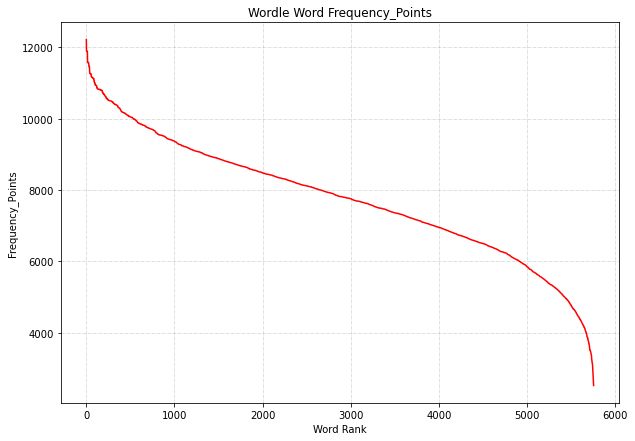

In [6]:
wordle_word_popularity = pd.DataFrame(sorted_usage.items(), columns = ["Word", "Frequency Points"])

ax2 = wordle_word_popularity.plot( legend = False , figsize = (10,7),  color = 'red')

ax2.set_ylabel("Frequency_Points")
ax2.set_xlabel("Word Rank")
ax2.set_title("Wordle Word Frequency_Points")
ax2.grid(b = True, color ='grey',
       linestyle ='-.', linewidth = 0.5,
        alpha = 0.5)

In [ ]:
guess = list(sorted_usage.keys())[0]
guess
guesses = ["arose"]
start = str(list(sorted_usage.keys()))
previous_code = "\'([^][^][^][^][^])\'"
left = None
possibilities_after_dict = {0: len(wordle_word_popularity)}
for i in range(5):
    if i != 0:
        previous_code = code
    print()
    print(f"Guess #{len(guesses)} was \'{guess}\' from possibilities of {previous_code}.")
    code = input("What are the new possibilities?")    
    if left == None:
        amount_left = len(re.findall(f"{code}", start))
        left = str(re.findall(f"{code}", start))
        print(left)
    else:
        amount_left = len(re.findall(f"{code}", start))
        left = str(re.findall(f"{code}", left))
    guess = left[2:7]
    possibilities_after_dict[len(guesses)] = amount_left
    guesses.append(guess)
    print()
    if amount_left != 1:
        print(f"Guess \'{guess}\' with {amount_left} options remaining.")
        continue        
    elif guesses[-2] == guess:
        print(f"The wordle is \'{guess.upper()}!\' Congrats you got it in {len(guesses)-1} guesses!")
        break
    else:
        print(f"The Wordle is \'{guess.upper()}!\' Congrats you got it in {len(guesses)} guesses!")
        break

df = pd.DataFrame(possibilities_after_dict.items(), columns = ["Guess #", "Possibilities Remaining"])
ax = df.plot.line(x="Guess #", y =  "Possibilities Remaining", legend = False, color = "red", figsize = (10,7))
ax.set_ylabel("Possibilities Remaining")
ax.set_title(f"\'{guess.upper()}\' Best Guess Graph")
ax.grid(b = True, color ='grey',
       linestyle ='-.', linewidth = 0.5,
        alpha = 0.5)


Guess #1 was 'arose' from possibilities of '([^][^][^][^][^])'.
What are the new possibilities?'([^roseplimchan][a][^roseplimchant][^roseplimch][^roseplimchnt])'
['tawny', 'gaudy', 'tagua', 'bawdy', 'fawny', 'tabby', 'taffy', 'fauna', 'gauzy', 'baddy', 'yawny', 'gawky', 'daffy', 'faddy', 'baggy', 'gabby', 'daddy', 'jaggy', 'kayak', 'jazzy']

Guess 'tawny' with 20 options remaining.

Guess #2 was 'tawny' from possibilities of '([^roseplimchan][a][^roseplimchant][^roseplimch][^roseplimchnt])'.
